# Unsupervised & Sequential Analysis for Credit Card Fraud Detection
**Units covered:** Unit 3 (K-means, Mixture of Gaussians with EM, Hierarchical clustering) and Unit 4 (Hidden Markov Model: maximum likelihood, forward-backward, scaling, Viterbi)

Every model is an **independent pipeline** on the same raw data and the same time-ordered split, and each one produces a *fraud score* for every test transaction. The last section compares them on common metrics.

**SMOTE** (the custom from-scratch SMOTE from `math_model.ipynb`, 7% target ratio, applied to the training data only) is reused here: K-means is fitted on the SMOTE-balanced training set, the two-class GMM learns its fraud component from real + synthetic fraud, and the HMM's fraud emissions are augmented with synthetic fraud symbols. The test set is never touched by SMOTE.

```
                     ┌→ K-means+SMOTE → cluster fraud-rate / centroid distance ─┐
Raw data → sort by   ├→ GMM (EM)     → legit NLL + two-class (SMOTE fraud)    ─┤
Time → scale →       ├→ HMM+SMOTE    → forward-backward P(Fraud), Viterbi     ─┼→ common metrics → comparison + plots
time-ordered split   └→ Hierarchical → (sample) analysis only                 ─┘
```
PCA is intentionally skipped because V1 to V28 in this dataset are already PCA components.

## 0. Setup

In [29]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logsumexp
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, confusion_matrix, matthews_corrcoef,
                             precision_score, recall_score, f1_score, silhouette_score,
                             adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---------------- CONFIG ----------------
DATA_PATH = Path(r"C:\abishek js\ML-Projects (3rd year)\Credit-Card_Fraud_detection\creditcard.csv")
if not DATA_PATH.exists():                 # fallback: csv placed next to the notebook
    DATA_PATH = Path("creditcard.csv")

SEED = 42
TRAIN_FRAC = 0.80            # time-ordered split (first 80% train, last 20% test)
# features chosen in the feature-selection stage of the project (+ Amount, the only non-PCA column)
SELECTED_FEATURES = ['V10', 'V11', 'V12', 'V14', 'V16', 'V17', 'V18', 'V2', 'V3', 'V4', 'V7', 'V9']
FEATURES = SELECTED_FEATURES + ["Amount"]

SMOTE_TARGET_RATIO = 0.07    # fraud share of the SMOTE-balanced training set (same as math_model.ipynb)
SMOTE_K = 5                  # nearest neighbours used by SMOTE

# ---- tuned values (chosen on a validation split inside the training data, see Section 7) ----
K_KMEANS = 20                # clusters for K-means (fitted on SMOTE-balanced train)
K_GMM = 12                   # GMM components for the legit model (None = pick by BIC from GMM_K_GRID)
GMM_K_GRID = [1, 2, 3, 5, 8, 10, 12, 16]
GMM_FRAUD_K = 2              # components of the fraud GMM in the two-class GMM
HMM_WINDOW = 10              # length of each observation sequence
HMM_N_TOP_FEATURES = 3       # number of V-features used (besides Amount) to build HMM symbols
HMM_SMOTE_WEIGHT = 0.5       # weight of synthetic fraud symbols in the HMM fraud emissions (0 = off)
HMM_N_SYNTHETIC = 5000       # synthetic fraud rows generated for the HMM emissions
RUN_SUPERVISED_REFERENCE = True   # adds a Random Forest row as a reference point
# ----------------------------------------
print("Using data file:", DATA_PATH)

Using data file: C:\abishek js\ML-Projects (3rd year)\Credit-Card_Fraud_detection\creditcard.csv


In [30]:
df = pd.read_csv(DATA_PATH).sort_values("Time").reset_index(drop=True)
feats = FEATURES

n = len(df)
split = int(n * TRAIN_FRAC)
train, test = df.iloc[:split].copy(), df.iloc[split:].copy()

scaler = StandardScaler().fit(train[feats])          # fit on train only (no leakage)
Xtr, Xte = scaler.transform(train[feats]), scaler.transform(test[feats])
ytr, yte = train["Class"].values, test["Class"].values
Xtr_legit = Xtr[ytr == 0]

summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "fraud": [ytr.sum(), yte.sum()],
    "fraud %": [100 * ytr.mean(), 100 * yte.mean()],
}, index=["train", "test"]).round(3)
summary

,rows,fraud,fraud %
train,227845,417,0.183
test,56962,75,0.132


### SMOTE on the training data (from `math_model.ipynb`)
Same from-scratch SMOTE as in the mathematical-model notebook: Euclidean k-nearest-neighbours among real fraud samples, then linear interpolation `x_new = x_i + lambda (x_nn - x_i)`. Synthetic points are generated from **training fraud only** (features already scaled with the train scaler).

In [31]:
def custom_smote(minority_X, n_synthetic, k=5, seed=42):
    """Basic SMOTE from scratch (Euclidean distance + linear interpolation)."""
    np.random.seed(seed)
    m, d = minority_X.shape
    diff = minority_X[:, np.newaxis, :] - minority_X[np.newaxis, :, :]
    dist_mat = np.sqrt(np.sum(diff ** 2, axis=-1))
    nn_indices = np.argsort(dist_mat, axis=1)[:, 1:k + 1]
    synthetic = np.empty((n_synthetic, d), dtype=np.float64)
    for i in range(n_synthetic):
        base_idx = np.random.randint(0, m)
        nn_idx = np.random.choice(nn_indices[base_idx])
        lam = np.random.uniform(0.0, 1.0)
        synthetic[i] = minority_X[base_idx] + lam * (minority_X[nn_idx] - minority_X[base_idx])
    return synthetic

n_tr_legit, n_tr_fraud = int((ytr == 0).sum()), int((ytr == 1).sum())
n_fraud_target = int((SMOTE_TARGET_RATIO / (1 - SMOTE_TARGET_RATIO)) * n_tr_legit)
n_to_generate = max(0, n_fraud_target - n_tr_fraud)

X_syn = custom_smote(Xtr[ytr == 1], n_to_generate, k=SMOTE_K, seed=SEED)
Xtr_bal = np.vstack([Xtr, X_syn])
ytr_bal = np.concatenate([ytr, np.ones(len(X_syn))])
N_REAL = len(Xtr)                      # the first N_REAL rows of Xtr_bal are the real training rows

print(f"Real fraud in train: {n_tr_fraud} | synthetic generated: {len(X_syn):,}")
print(f"Balanced train set: {int((ytr_bal==0).sum()):,} legit, {int((ytr_bal==1).sum()):,} fraud "
      f"({100*ytr_bal.mean():.2f}% fraud)")

Real fraud in train: 417 | synthetic generated: 16,701
Balanced train set: 227,428 legit, 17,118 fraud (7.00% fraud)


### Evaluation helper
Every model returns a **score** (higher = more fraud-like). Metrics:
- **PR-AUC (average precision)**: main metric for severe imbalance, threshold-free.
- **ROC-AUC**: threshold-free ranking quality.
- **Precision@k** (k = number of real frauds in test) and **Recall@1%** (fraud caught when only the top 1% riskiest transactions are flagged): threshold-free and easy to explain.
- **Precision / Recall / F1 / MCC / confusion matrix** at an operating point. For score-based models the operating point is the *best-F1 threshold* (an oracle threshold, so it is optimistic). For the HMM-Viterbi row it is the model's real hard decision.

In [32]:
results, scores, preds = [], {}, {}

def evaluate(name, score, y_true, hard_pred=None, group="Unsupervised"):
    k = int(y_true.sum())
    if hard_pred is None:
        score = np.asarray(score, dtype=float)
        ap, auc = average_precision_score(y_true, score), roc_auc_score(y_true, score)
        p, r, t = precision_recall_curve(y_true, score)
        f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        best_f1, thr = f1s.max(), t[f1s.argmax()]
        order = np.argsort(-score, kind="stable")
        prec_at_k = y_true[order[:k]].mean()
        rec_at_1pct = y_true[order[: int(0.01 * len(score))]].sum() / y_true.sum()
        pred = score >= thr
        scores[name] = score
    else:                                   # hard decision (e.g. Viterbi): no score, so no threshold-free metrics
        ap = auc = best_f1 = prec_at_k = rec_at_1pct = np.nan
        pred = np.asarray(hard_pred).astype(bool)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    results.append({
        "Model": name, "Group": group, "PR-AUC": ap, "ROC-AUC": auc, "Best F1": best_f1,
        f"Precision@{k}": prec_at_k, "Recall@1%": rec_at_1pct,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Operating point": "best-F1 threshold" if hard_pred is None else "model decision",
    })
    preds[name] = pred
    return pd.DataFrame(results[-1:]).set_index("Model").round(4)

## 1. K-means clustering (Unit 3)
K-means is written from scratch in NumPy (k-means++ initialisation, Lloyd iterations). It is fitted on the **SMOTE-balanced training set** (so fraud forms its own dense clusters). Cluster fraud-rates are then measured on the **real** training rows only, so synthetic points never inflate the rates.

Two fraud scores come out of it:
1. **Cluster fraud-rate**: a test transaction gets the (smoothed) fraud rate of its nearest cluster, learned on train.
2. **Centroid distance**: distance to the nearest centroid (far from every cluster means unusual).

In [33]:
def kmeanspp_init(X, k, rng):
    centers = [X[rng.integers(len(X))]]
    d2 = ((X - centers[0]) ** 2).sum(1)
    for _ in range(1, k):
        c = X[rng.choice(len(X), p=d2 / d2.sum())]
        centers.append(c)
        d2 = np.minimum(d2, ((X - c) ** 2).sum(1))
    return np.array(centers)

def sq_dists(X, C):
    return (X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :]

def kmeans(X, k, max_iter=100, tol=1e-4, seed=SEED):
    rng = np.random.default_rng(seed)
    C = kmeanspp_init(X, k, rng)
    for _ in range(max_iter):
        labels = sq_dists(X, C).argmin(1)
        newC = C.copy()
        for j in range(k):
            m = labels == j
            if m.any():
                newC[j] = X[m].mean(0)
        shift = np.abs(newC - C).max()
        C = newC
        if shift < tol:
            break
    D = sq_dists(X, C)
    labels = D.argmin(1)
    return C, labels, D[np.arange(len(X)), labels].sum()

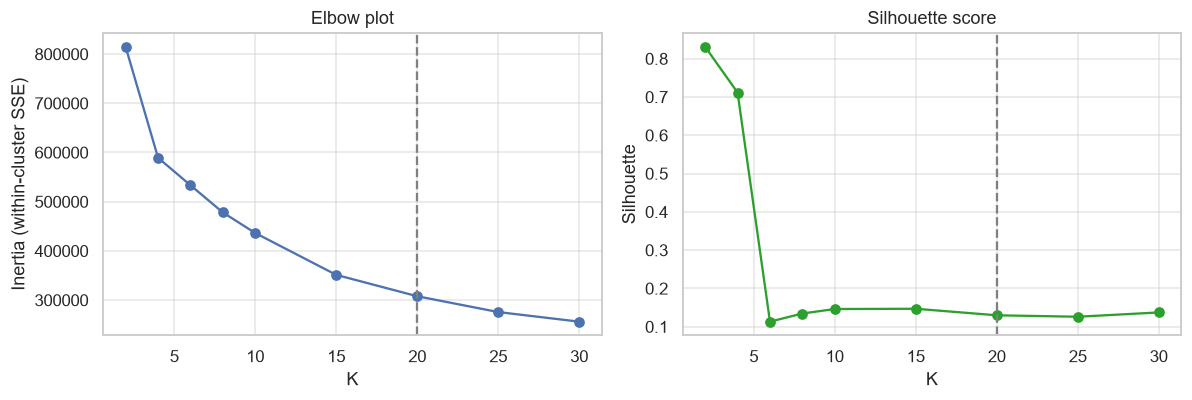

In [34]:
# Choose K: elbow (inertia) + silhouette on a subsample of train
rng = np.random.default_rng(SEED)
sub = Xtr_bal[rng.choice(len(Xtr_bal), 40000, replace=False)]
ks, inertias, sils = [2, 4, 6, 8, 10, 15, 20, 25, 30], [], []
for k in ks:
    C_, lab_, inertia_ = kmeans(sub, k)
    inertias.append(inertia_)
    sils.append(silhouette_score(sub, lab_, sample_size=5000, random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, inertias, "o-"); ax[0].set(title="Elbow plot", xlabel="K", ylabel="Inertia (within-cluster SSE)")
ax[1].plot(ks, sils, "o-", color="tab:green"); ax[1].set(title="Silhouette score", xlabel="K", ylabel="Silhouette")
for a in ax: a.axvline(K_KMEANS, ls="--", color="grey")
plt.tight_layout(); plt.show()

K-means fitted in 19.7s


,size,frauds,fraud rate %
0,19919,3,0.015
1,76,61,80.263
2,2189,25,1.142
3,23,23,100.000
4,64970,8,0.012
5,17,17,100.000
6,63,54,85.714
7,43,41,95.349
8,16098,2,0.012
9,2462,0,0.000


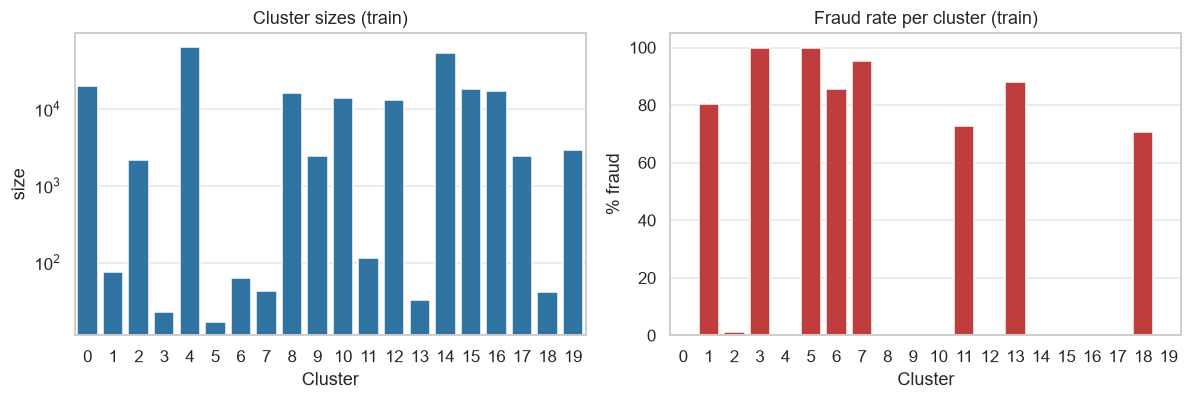

In [35]:
t0 = time.time()
centers, bal_lab, _ = kmeans(Xtr_bal, K_KMEANS)
tr_lab = bal_lab[:N_REAL]                             # cluster of each REAL training row
te_lab = sq_dists(Xte, centers).argmin(1)
print(f"K-means fitted in {time.time()-t0:.1f}s")

# fraud rate per cluster, learned from REAL train labels only
prior, a = ytr.mean(), 5.0
size = np.bincount(tr_lab, minlength=K_KMEANS)
fraud_n = np.bincount(tr_lab, weights=ytr, minlength=K_KMEANS)
smoothed_rate = (fraud_n + a * prior) / (size + a)

cluster_table = pd.DataFrame({"size": size, "frauds": fraud_n.astype(int),
                              "fraud rate %": 100 * fraud_n / np.maximum(size, 1)}).round(3)
display(cluster_table)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=cluster_table.index, y=cluster_table["size"], ax=ax[0], color="tab:blue")
ax[0].set(title="Cluster sizes (train)", xlabel="Cluster", yscale="log")
sns.barplot(x=cluster_table.index, y=cluster_table["fraud rate %"], ax=ax[1], color="tab:red")
ax[1].set(title="Fraud rate per cluster (train)", xlabel="Cluster", ylabel="% fraud")
plt.tight_layout(); plt.show()

In [36]:
km_rate_score = smoothed_rate[te_lab]
km_dist_score = np.sqrt(sq_dists(Xte, centers).min(1))

display(evaluate("K-means+SMOTE (cluster fraud-rate)", km_rate_score, yte))
display(evaluate("K-means+SMOTE (centroid distance)", km_dist_score, yte))

,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
K-means+SMOTE (cluster fraud-rate),Unsupervised,0.7342,0.9636,0.8058,0.7467,0.8533,0.875,0.7467,0.8058,0.8081,56,8,19,56879,best-F1 threshold


,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
K-means+SMOTE (centroid distance),Unsupervised,0.0197,0.9087,0.0674,0.0,0.2267,0.0405,0.2,0.0674,0.0875,15,355,60,56532,best-F1 threshold


## 2. Mixture of Gaussians with EM (Unit 3)
EM is written from scratch (diagonal covariances, log-sum-exp for numerical stability).
- **E-step:** responsibilities `r_nk = pi_k N(x_n | mu_k, S_k) / sum_j pi_j N(x_n | mu_j, S_j)`
- **M-step:** update `pi_k`, `mu_k`, `S_k` using the responsibilities
- The GMM is fitted on **legitimate transactions only** (so it learns what normal looks like). Fraud score = **negative log-likelihood**, so a transaction that the normal-model finds unlikely is flagged.
- Number of components K is chosen by **BIC** (lower is better).

In [37]:
class DiagGMM:
    def __init__(self, k, max_iter=100, tol=1e-4, reg=1e-3, seed=SEED):
        self.k, self.max_iter, self.tol, self.reg, self.seed = k, max_iter, tol, reg, seed
        self.history = []

    def _log_joint(self, X):                      # log( pi_k * N(x | mu_k, diag var_k) )
        inv = 1.0 / self.var
        quad = (X ** 2) @ inv.T - 2 * X @ (self.mu * inv).T + (self.mu ** 2 * inv).sum(1)
        logdet = np.log(2 * np.pi * self.var).sum(1)
        return np.log(self.w) - 0.5 * (logdet + quad)

    def fit(self, X):
        n, d = X.shape
        C, lab, _ = kmeans(X, self.k, max_iter=20, seed=self.seed)     # initialise from K-means
        gvar = X.var(0) + self.reg
        self.mu = C
        self.w = np.maximum(np.bincount(lab, minlength=self.k) / n, 1e-6)
        self.w /= self.w.sum()
        self.var = np.array([X[lab == j].var(0) + self.reg if (lab == j).sum() > 1 else gvar
                             for j in range(self.k)])
        prev = -np.inf
        for it in range(self.max_iter):
            lj = self._log_joint(X)
            ll_i = logsumexp(lj, axis=1)
            resp = np.exp(lj - ll_i[:, None])                           # E-step
            ll = ll_i.mean(); self.history.append(ll)
            Nk = resp.sum(0) + 1e-10                                    # M-step
            self.w = Nk / n
            self.mu = (resp.T @ X) / Nk[:, None]
            self.var = np.maximum((resp.T @ X ** 2) / Nk[:, None] - self.mu ** 2, self.reg)
            if abs(ll - prev) < self.tol:
                break
            prev = ll
        return self

    def score_samples(self, X):                   # log p(x)
        return logsumexp(self._log_joint(X), axis=1)

    def bic(self, X):
        n, d = X.shape
        n_params = self.k * d * 2 + (self.k - 1)
        return -2 * self.score_samples(X).sum() + n_params * np.log(n)

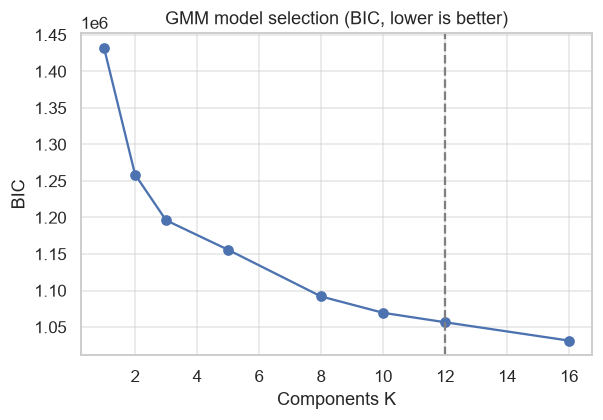

Components used: 12


In [38]:
# choose K by BIC on a subsample of legit train data
rng = np.random.default_rng(SEED)
sub = Xtr_legit[rng.choice(len(Xtr_legit), 40000, replace=False)]
bics = []
for k in GMM_K_GRID:
    g = DiagGMM(k).fit(sub)
    bics.append(g.bic(sub))
best_k = GMM_K_GRID[int(np.argmin(bics))]
K_GMM_USED = K_GMM or best_k

plt.figure(figsize=(6, 3.8))
plt.plot(GMM_K_GRID, bics, "o-"); plt.axvline(K_GMM_USED, ls="--", color="grey")
plt.title("GMM model selection (BIC, lower is better)"); plt.xlabel("Components K"); plt.ylabel("BIC")
plt.show()
print("Components used:", K_GMM_USED)

EM finished in 99 iterations, 46.6s


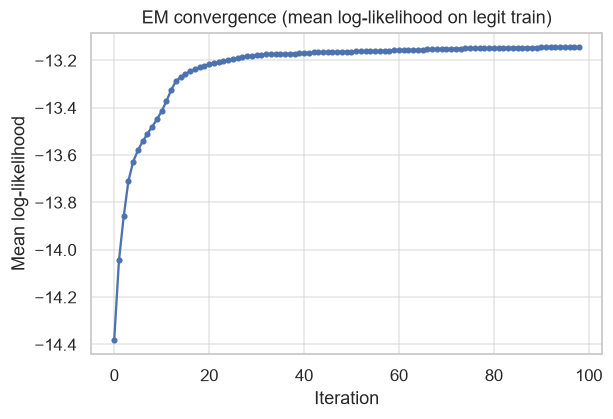

Mean log-lik  scratch EM: -13.165 | sklearn: -13.307


In [39]:
t0 = time.time()
gmm = DiagGMM(K_GMM_USED, max_iter=150).fit(Xtr_legit)
print(f"EM finished in {len(gmm.history)} iterations, {time.time()-t0:.1f}s")

plt.figure(figsize=(6, 3.8))
plt.plot(gmm.history, "o-", ms=3)
plt.title("EM convergence (mean log-likelihood on legit train)"); plt.xlabel("Iteration"); plt.ylabel("Mean log-likelihood")
plt.show()

# sanity check against scikit-learn's implementation on the same subsample
from sklearn.mixture import GaussianMixture
chk = DiagGMM(K_GMM_USED).fit(sub)
sk = GaussianMixture(K_GMM_USED, covariance_type="diag", reg_covar=1e-3, random_state=SEED).fit(sub)
print(f"Mean log-lik  scratch EM: {chk.score_samples(sub).mean():.3f} | sklearn: {sk.score(sub):.3f}")

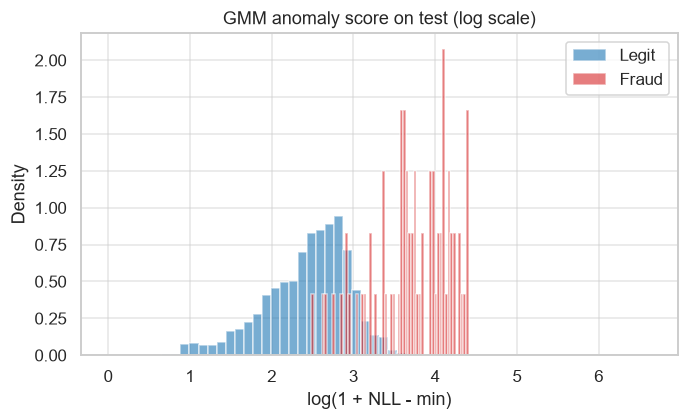

,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
"GMM (EM, diag, legit-only)",Unsupervised,0.3443,0.9643,0.4961,0.4533,0.76,0.5926,0.4267,0.4961,0.5023,32,22,43,56865,best-F1 threshold


In [40]:
gmm_score = -gmm.score_samples(Xte)

fig, ax = plt.subplots(figsize=(7, 3.8))
for cls, lab, col in [(0, "Legit", "tab:blue"), (1, "Fraud", "tab:red")]:
    ax.hist(np.log1p(gmm_score[yte == cls] - gmm_score.min()), bins=60, alpha=.6, density=True, label=lab, color=col)
ax.set(title="GMM anomaly score on test (log scale)", xlabel="log(1 + NLL - min)", ylabel="Density"); ax.legend()
plt.show()

display(evaluate("GMM (EM, diag, legit-only)", gmm_score, yte))

In [41]:
# Extra variant: full-covariance GMM (scikit-learn) on legit data, for comparison with our diagonal EM
gmm_full = GaussianMixture(n_components=min(K_GMM_USED, 5), covariance_type="full", reg_covar=1e-3,
                           random_state=SEED, max_iter=100).fit(Xtr_legit)
display(evaluate("GMM (full cov, sklearn)", -gmm_full.score_samples(Xte), yte))

,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
"GMM (full cov, sklearn)",Unsupervised,0.7035,0.976,0.7519,0.7333,0.8,0.8621,0.6667,0.7519,0.7578,50,8,25,56879,best-F1 threshold


### Two-class GMM using SMOTE fraud
A second GMM is fitted on the fraud class (real + synthetic fraud from SMOTE). The score is the log-likelihood ratio `log p(x | fraud) - log p(x | legit)`, so a transaction is flagged when the fraud model explains it better than the legit model.

In [42]:
fraud_X = Xtr_bal[ytr_bal == 1]
gmm_fraud = DiagGMM(GMM_FRAUD_K, max_iter=150).fit(fraud_X)
print(f"Fraud GMM: {GMM_FRAUD_K} components fitted on {len(fraud_X):,} fraud rows (real + synthetic)")

gmm2_score = gmm_fraud.score_samples(Xte) - gmm.score_samples(Xte)
display(evaluate("GMM two-class (SMOTE fraud vs legit)", gmm2_score, yte))

Fraud GMM: 2 components fitted on 17,118 fraud rows (real + synthetic)


,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
GMM two-class (SMOTE fraud vs legit),Unsupervised,0.7325,0.9675,0.75,0.7333,0.8133,1.0,0.6,0.75,0.7744,45,0,30,56887,best-F1 threshold


## 3. Hidden Markov Model (Unit 4)
| HMM part | In this project |
|---|---|
| Hidden states | 0 = Normal, 1 = Fraud |
| Observation symbols | Discretised transaction features (quantile bins of Amount and the most fraud-related V-features) |
| Sequences | The time-ordered transaction stream cut into windows of `HMM_WINDOW` transactions |
| Training | **Maximum likelihood by counting** (labels give the states), with Laplace smoothing. Fraud emissions are also augmented with SMOTE-generated fraud symbols |
| Fraud score | **Forward-backward** posterior `P(state = Fraud | window)` with scaling factors |
| Hard decision | **Viterbi** most likely state sequence |

The HMM uses its own discretisation and does not depend on K-means.

> Limitation: the dataset has no cardholder ID, so the sequence is the global time-ordered transaction stream, not one card's history.

In [43]:
# --- 3.1 discretisation (bin edges learned on TRAIN only) ---
v_cols = [f"V{i}" for i in range(1, 29)]
corr = train[v_cols].corrwith(train["Class"]).abs().sort_values(ascending=False)
top_feats = list(corr.index[:HMM_N_TOP_FEATURES])
print("V-features used for symbols:", top_feats)

quantiles = {"Amount": [0.50, 0.90]}
quantiles.update({f: [0.02, 0.10, 0.90, 0.98] for f in top_feats})
edges = {f: np.quantile(train[f], q) for f, q in quantiles.items()}
n_bins = [len(edges[f]) + 1 for f in quantiles]
N_SYMBOLS = int(np.prod(n_bins))

def discretise(frame):
    idx = [np.digitize(frame[f].values, edges[f]) for f in quantiles]
    return np.ravel_multi_index(idx, n_bins)

tr_obs, te_obs = discretise(train), discretise(test)
print("Number of observation symbols:", N_SYMBOLS)

V-features used for symbols: ['V17', 'V14', 'V12']
Number of observation symbols: 375


In [44]:
# --- 3.2 maximum-likelihood training (counting) ---
def to_windows(a, L):
    m = len(a) // L * L
    return a[:m].reshape(-1, L), a[m:]

def fit_hmm(O, S, n_states=2, n_obs=N_SYMBOLS, smooth=1.0):
    start = np.full(n_states, smooth); trans = np.full((n_states, n_states), smooth)
    emit = np.full((n_states, n_obs), smooth)
    np.add.at(start, S[:, 0], 1)
    np.add.at(trans, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    np.add.at(emit, (S.ravel(), O.ravel()), 1)
    return start / start.sum(), trans / trans.sum(1, keepdims=True), emit / emit.sum(1, keepdims=True)

tr_O, _ = to_windows(tr_obs, HMM_WINDOW)
tr_S, _ = to_windows(ytr, HMM_WINDOW)
start_p, trans_p, emit_p = fit_hmm(tr_O, tr_S)

print("Start probabilities (Normal, Fraud):", start_p.round(5))
print("Transition matrix A (rows = from, cols = to):"); print(trans_p.round(5))

# --- SMOTE-augmented fraud emissions (synthetic fraud generated in the raw HMM feature space) ---
if HMM_SMOTE_WEIGHT > 0:
    fcols = list(quantiles)
    syn_raw = custom_smote(train.loc[train["Class"] == 1, fcols].values, HMM_N_SYNTHETIC, k=SMOTE_K, seed=SEED)
    syn_obs = discretise(pd.DataFrame(syn_raw, columns=fcols))
    fraud_counts = (np.bincount(tr_obs[ytr == 1], minlength=N_SYMBOLS) + 1.0
                    + HMM_SMOTE_WEIGHT * np.bincount(syn_obs, minlength=N_SYMBOLS))
    emit_p[1] = fraud_counts / fraud_counts.sum()
    print(f"Fraud emissions augmented with {HMM_N_SYNTHETIC:,} synthetic fraud rows (weight {HMM_SMOTE_WEIGHT})")

Start probabilities (Normal, Fraud): [0.9982 0.0018]
Transition matrix A (rows = from, cols = to):
[[0.99828 0.00172]
 [0.93048 0.06952]]
Fraud emissions augmented with 5,000 synthetic fraud rows (weight 0.5)


In [45]:
# --- 3.3 forward-backward (with scaling factors) and Viterbi, vectorised over windows ---
def forward_backward(O, start, A, B):
    W, T = O.shape; N = len(start)
    alpha, c = np.zeros((W, T, N)), np.zeros((W, T))
    a0 = start[None, :] * B[:, O[:, 0]].T
    c[:, 0] = a0.sum(1); alpha[:, 0] = a0 / c[:, 0, None]
    for t in range(1, T):
        a_t = (alpha[:, t - 1] @ A) * B[:, O[:, t]].T
        c[:, t] = a_t.sum(1); alpha[:, t] = a_t / c[:, t, None]
    beta = np.ones((W, T, N))
    for t in range(T - 2, -1, -1):
        beta[:, t] = ((B[:, O[:, t + 1]].T * beta[:, t + 1]) @ A.T) / c[:, t + 1, None]
    gamma = alpha * beta
    gamma /= gamma.sum(2, keepdims=True)
    return gamma, np.log(c).sum(1)             # state posteriors, log-likelihood per window

def viterbi(O, start, A, B):
    W, T = O.shape; N = len(start)
    lA, lB = np.log(A), np.log(B)
    delta, psi = np.zeros((W, T, N)), np.zeros((W, T, N), dtype=int)
    delta[:, 0] = np.log(start)[None, :] + lB[:, O[:, 0]].T
    for t in range(1, T):
        cand = delta[:, t - 1, :, None] + lA[None, :, :]
        psi[:, t] = cand.argmax(1)
        delta[:, t] = cand.max(1) + lB[:, O[:, t]].T
    path = np.zeros((W, T), dtype=int)
    path[:, -1] = delta[:, -1].argmax(1)
    for t in range(T - 2, -1, -1):
        path[:, t] = psi[np.arange(W), t + 1, path[:, t + 1]]
    return path

def hmm_infer(obs):
    full, tail = to_windows(obs, HMM_WINDOW)
    g, _ = forward_backward(full, start_p, trans_p, emit_p)
    post, path = g[:, :, 1].ravel(), viterbi(full, start_p, trans_p, emit_p).ravel()
    if len(tail):                              # last partial window, so every test row is scored
        gt, _ = forward_backward(tail[None, :], start_p, trans_p, emit_p)
        post = np.concatenate([post, gt[0, :, 1]])
        path = np.concatenate([path, viterbi(tail[None, :], start_p, trans_p, emit_p)[0]])
    return post, path

hmm_post, hmm_path = hmm_infer(te_obs)
print("Scored rows:", len(hmm_post), "| test rows:", len(yte))

Scored rows: 56962 | test rows: 56962


In [46]:
display(evaluate("HMM+SMOTE (forward-backward P(Fraud))", hmm_post, yte))
display(evaluate("HMM+SMOTE (Viterbi decision)", None, yte, hard_pred=hmm_path))

,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
HMM+SMOTE (forward-backward P(Fraud)),Unsupervised,0.679,0.9656,0.7714,0.7333,0.7867,0.8308,0.72,0.7714,0.7731,54,11,21,56876,best-F1 threshold


,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
HMM+SMOTE (Viterbi decision),Unsupervised,NaN,NaN,NaN,NaN,NaN,0.9184,0.6,0.7258,0.7421,45,4,30,56883,model decision


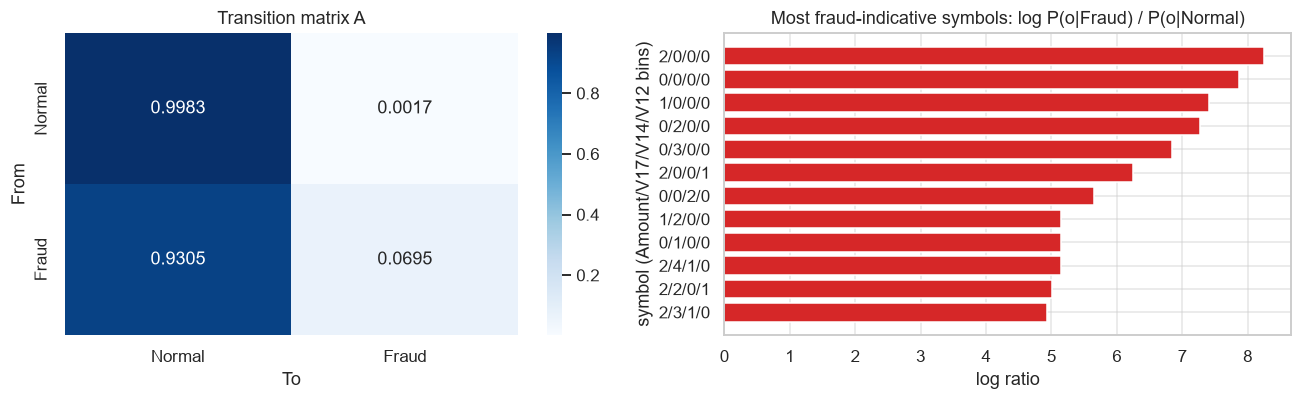

In [47]:
# --- 3.4 HMM visualisations ---
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(trans_p, annot=True, fmt=".4f", cmap="Blues", ax=ax[0],
            xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
ax[0].set(title="Transition matrix A", xlabel="To", ylabel="From")

ratio = np.log(emit_p[1] / emit_p[0])
top = np.argsort(-ratio)[:12]
labels = ["/".join(map(str, np.unravel_index(s, n_bins))) for s in top]
ax[1].barh(labels[::-1], ratio[top][::-1], color="tab:red")
ax[1].set(title="Most fraud-indicative symbols: log P(o|Fraud) / P(o|Normal)",
          xlabel="log ratio", ylabel="symbol (" + "/".join(quantiles) + " bins)")
plt.tight_layout(); plt.show()

## 4. Hierarchical clustering (Unit 3, analysis only)
Hierarchical clustering needs a full distance matrix (memory grows with n squared), so it is run on a **stratified sample** of the training data (all-legit sample plus fraud). It has no natural "predict a new point" step, so it is analysed with a dendrogram and cluster purity and is **not** included in the final score comparison.

Sample: 1600 rows (100 fraud) | cophenetic correlation: 0.855


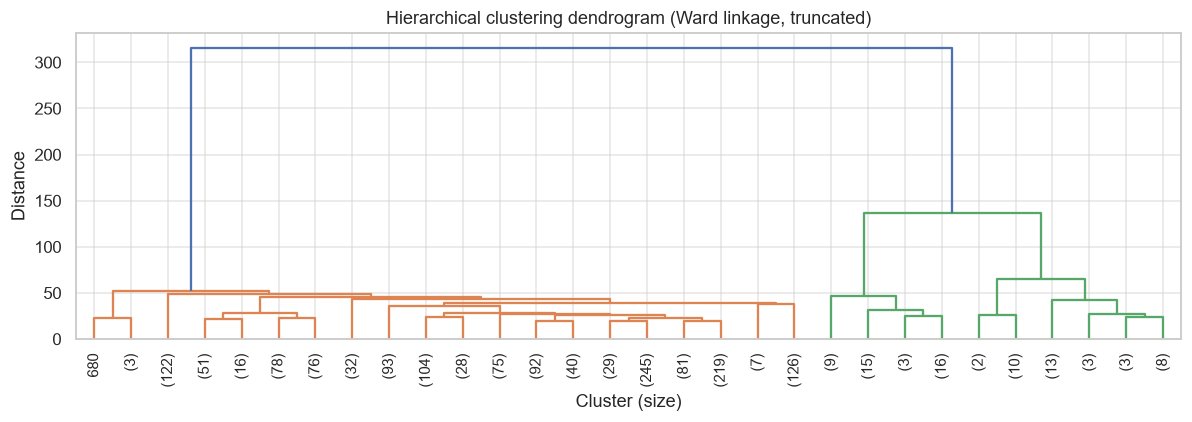

In [48]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

rng = np.random.default_rng(SEED)
idx_f = np.where(ytr == 1)[0]
idx_l = rng.choice(np.where(ytr == 0)[0], 1500, replace=False)
idx = np.concatenate([idx_l, rng.choice(idx_f, 100, replace=False)])
Xs, ys = Xtr[idx], ytr[idx]

Z = linkage(Xs, method="ward")
coph, _ = cophenet(Z, pdist(Xs))
print(f"Sample: {len(Xs)} rows ({ys.sum()} fraud) | cophenetic correlation: {coph:.3f}")

plt.figure(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_leaf_counts=True, no_labels=False)
plt.title("Hierarchical clustering dendrogram (Ward linkage, truncated)"); plt.xlabel("Cluster (size)"); plt.ylabel("Distance")
plt.tight_layout(); plt.show()

In [49]:
H_K = 8
hc = fcluster(Z, H_K, criterion="maxclust")
tab = pd.DataFrame({"cluster": hc, "fraud": ys}).groupby("cluster")["fraud"].agg(["size", "sum"])
tab.columns = ["size", "frauds"]; tab["fraud rate %"] = 100 * tab["frauds"] / tab["size"]
display(tab.round(2))

purity = tab[["frauds", "size"]].apply(lambda r: max(r["frauds"], r["size"] - r["frauds"]), axis=1).sum() / len(ys)
print(f"Purity: {purity:.3f} (a trivial 'all legit' baseline gives {1 - ys.mean():.3f})")
print(f"Adjusted Rand Index vs Class: {adjusted_rand_score(ys, hc):.3f}")

,size,frauds,fraud rate %
cluster,,,
1,4,0,0.00
2,122,2,1.64
3,221,0,0.00
4,1171,17,1.45
5,9,9,100.00
6,34,33,97.06
7,12,12,100.00
8,27,27,100.00


Purity: 0.988 (a trivial 'all legit' baseline gives 0.938)
Adjusted Rand Index vs Class: 0.222


## 5. Optional reference: supervised Random Forest
Not part of Unit 3/4. A Random Forest trained on the same SMOTE-balanced data as `math_model.ipynb` is added only so the plots show how far the unit-3/4 methods are from a supervised model.

In [50]:
if RUN_SUPERVISED_REFERENCE:
    from sklearn.ensemble import RandomForestClassifier
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED).fit(Xtr_bal, ytr_bal)
    print(f"RF trained in {time.time()-t0:.1f}s")
    display(evaluate("Random Forest (supervised ref.)", rf.predict_proba(Xte)[:, 1], yte, group="Supervised reference"))

RF trained in 18.2s


,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,,,,,,,
Random Forest (supervised ref.),Supervised reference,0.8112,0.9893,0.8462,0.7733,0.8533,1.0,0.7333,0.8462,0.8562,55,0,20,56887,best-F1 threshold


## 6. Comparison of all models
Same raw data, same time-ordered split, same test rows for every model.

In [51]:
res = pd.DataFrame(results).set_index("Model")
k_real = int(yte.sum())
main_cols = ["Group", "PR-AUC", "ROC-AUC", "Best F1", f"Precision@{k_real}", "Recall@1%"]
op_cols = ["Precision", "Recall", "F1", "MCC", "TP", "FP", "FN", "TN", "Operating point"]

print("Threshold-free metrics (sorted by PR-AUC)")
display(res[main_cols].dropna(subset=["PR-AUC"]).sort_values("PR-AUC", ascending=False).round(4))
print("Metrics at the operating point")
display(res[op_cols].sort_values("F1", ascending=False).round(4))

Threshold-free metrics (sorted by PR-AUC)


,Group,PR-AUC,ROC-AUC,Best F1,Precision@75,Recall@1%
Model,,,,,,
Random Forest (supervised ref.),Supervised reference,0.8112,0.9893,0.8462,0.7733,0.8533
K-means+SMOTE (cluster fraud-rate),Unsupervised,0.7342,0.9636,0.8058,0.7467,0.8533
GMM two-class (SMOTE fraud vs legit),Unsupervised,0.7325,0.9675,0.7500,0.7333,0.8133
"GMM (full cov, sklearn)",Unsupervised,0.7035,0.9760,0.7519,0.7333,0.8000
HMM+SMOTE (forward-backward P(Fraud)),Unsupervised,0.6790,0.9656,0.7714,0.7333,0.7867
"GMM (EM, diag, legit-only)",Unsupervised,0.3443,0.9643,0.4961,0.4533,0.7600
K-means+SMOTE (centroid distance),Unsupervised,0.0197,0.9087,0.0674,0.0000,0.2267


Metrics at the operating point


,Precision,Recall,F1,MCC,TP,FP,FN,TN,Operating point
Model,,,,,,,,,
Random Forest (supervised ref.),1.0000,0.7333,0.8462,0.8562,55,0,20,56887,best-F1 threshold
K-means+SMOTE (cluster fraud-rate),0.8750,0.7467,0.8058,0.8081,56,8,19,56879,best-F1 threshold
HMM+SMOTE (forward-backward P(Fraud)),0.8308,0.7200,0.7714,0.7731,54,11,21,56876,best-F1 threshold
"GMM (full cov, sklearn)",0.8621,0.6667,0.7519,0.7578,50,8,25,56879,best-F1 threshold
GMM two-class (SMOTE fraud vs legit),1.0000,0.6000,0.7500,0.7744,45,0,30,56887,best-F1 threshold
HMM+SMOTE (Viterbi decision),0.9184,0.6000,0.7258,0.7421,45,4,30,56883,model decision
"GMM (EM, diag, legit-only)",0.5926,0.4267,0.4961,0.5023,32,22,43,56865,best-F1 threshold
K-means+SMOTE (centroid distance),0.0405,0.2000,0.0674,0.0875,15,355,60,56532,best-F1 threshold


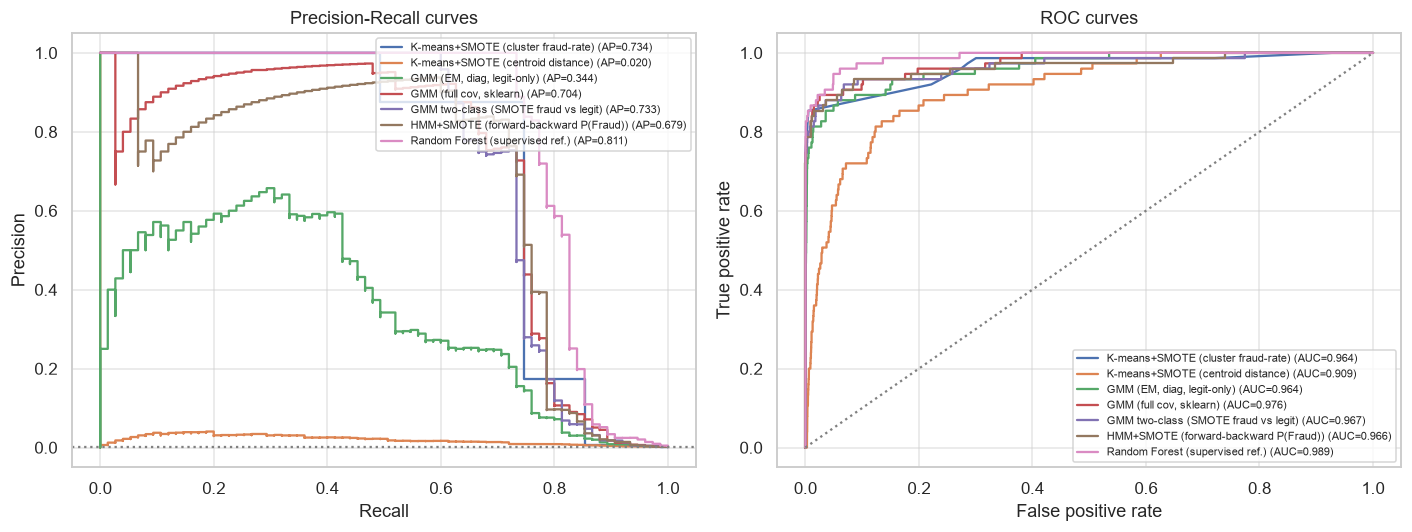

In [52]:
# Precision-Recall and ROC curves
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(yte, s)
    ax[0].plot(r, p, drawstyle="steps-post", label=f"{name} (AP={res.loc[name, 'PR-AUC']:.3f})")
    fpr, tpr, _ = roc_curve(yte, s)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={res.loc[name, 'ROC-AUC']:.3f})")
ax[0].axhline(yte.mean(), ls=":", color="grey")
ax[0].set(title="Precision-Recall curves", xlabel="Recall", ylabel="Precision")
ax[1].plot([0, 1], [0, 1], ls=":", color="grey")
ax[1].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(fontsize=7, loc="upper right"); ax[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

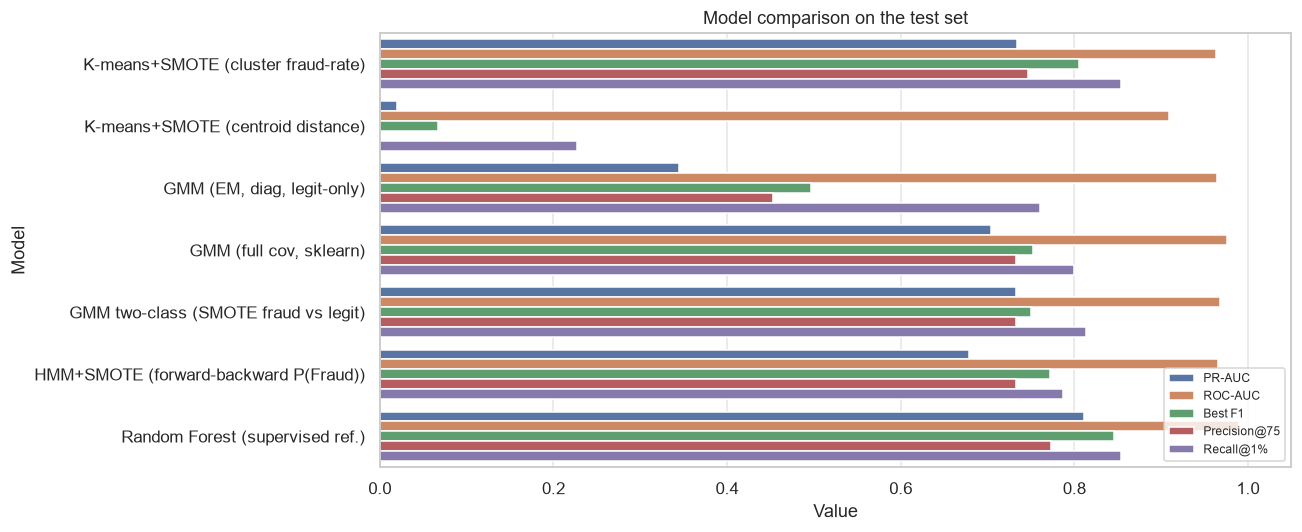

In [53]:
# Bar chart of key metrics
metrics_to_plot = ["PR-AUC", "ROC-AUC", "Best F1", f"Precision@{k_real}", "Recall@1%"]
plot_df = res[metrics_to_plot].dropna().reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, y="Model", x="Value", hue="Metric")
plt.title("Model comparison on the test set"); plt.xlim(0, 1.05); plt.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

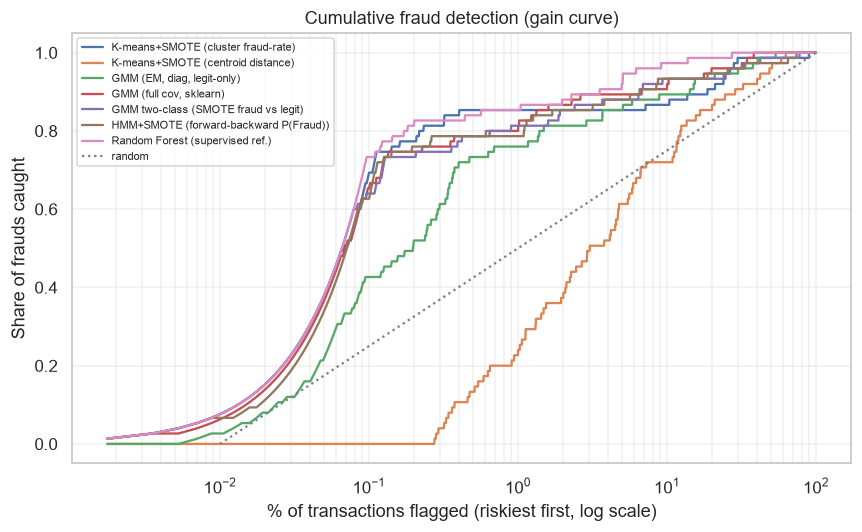

In [54]:
# How does each model detect fraud? Cumulative gain: share of fraud caught vs share of transactions flagged
plt.figure(figsize=(8, 5))
for name, s in scores.items():
    order = np.argsort(-s, kind="stable")
    caught = np.cumsum(yte[order]) / yte.sum()
    plt.plot(100 * np.arange(1, len(s) + 1) / len(s), caught, label=name)
plt.plot([0.01, 100], [0.0001, 1], ls=":", color="grey", label="random")
plt.xscale("log"); plt.xlabel("% of transactions flagged (riskiest first, log scale)"); plt.ylabel("Share of frauds caught")
plt.title("Cumulative fraud detection (gain curve)"); plt.legend(fontsize=7); plt.grid(True, which="both", alpha=.3)
plt.tight_layout(); plt.show()

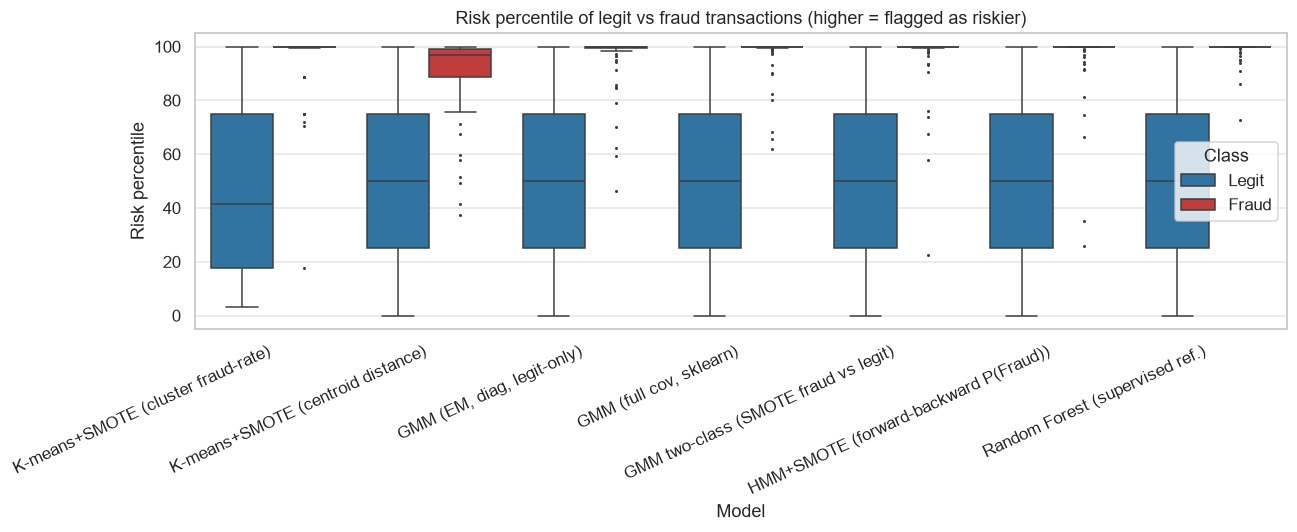

In [55]:
# Where do real frauds rank? (percentile of risk score; 100 = riskiest)
pct_df = pd.concat([pd.DataFrame({"Model": name, "Class": np.where(yte == 1, "Fraud", "Legit"),
                                  "Risk percentile": 100 * rankdata(s) / len(s)})
                    for name, s in scores.items()])
plt.figure(figsize=(12, 5))
sns.boxplot(data=pct_df, x="Model", y="Risk percentile", hue="Class", palette={"Legit": "tab:blue", "Fraud": "tab:red"},
            fliersize=1)
plt.xticks(rotation=25, ha="right"); plt.title("Risk percentile of legit vs fraud transactions (higher = flagged as riskier)")
plt.tight_layout(); plt.show()

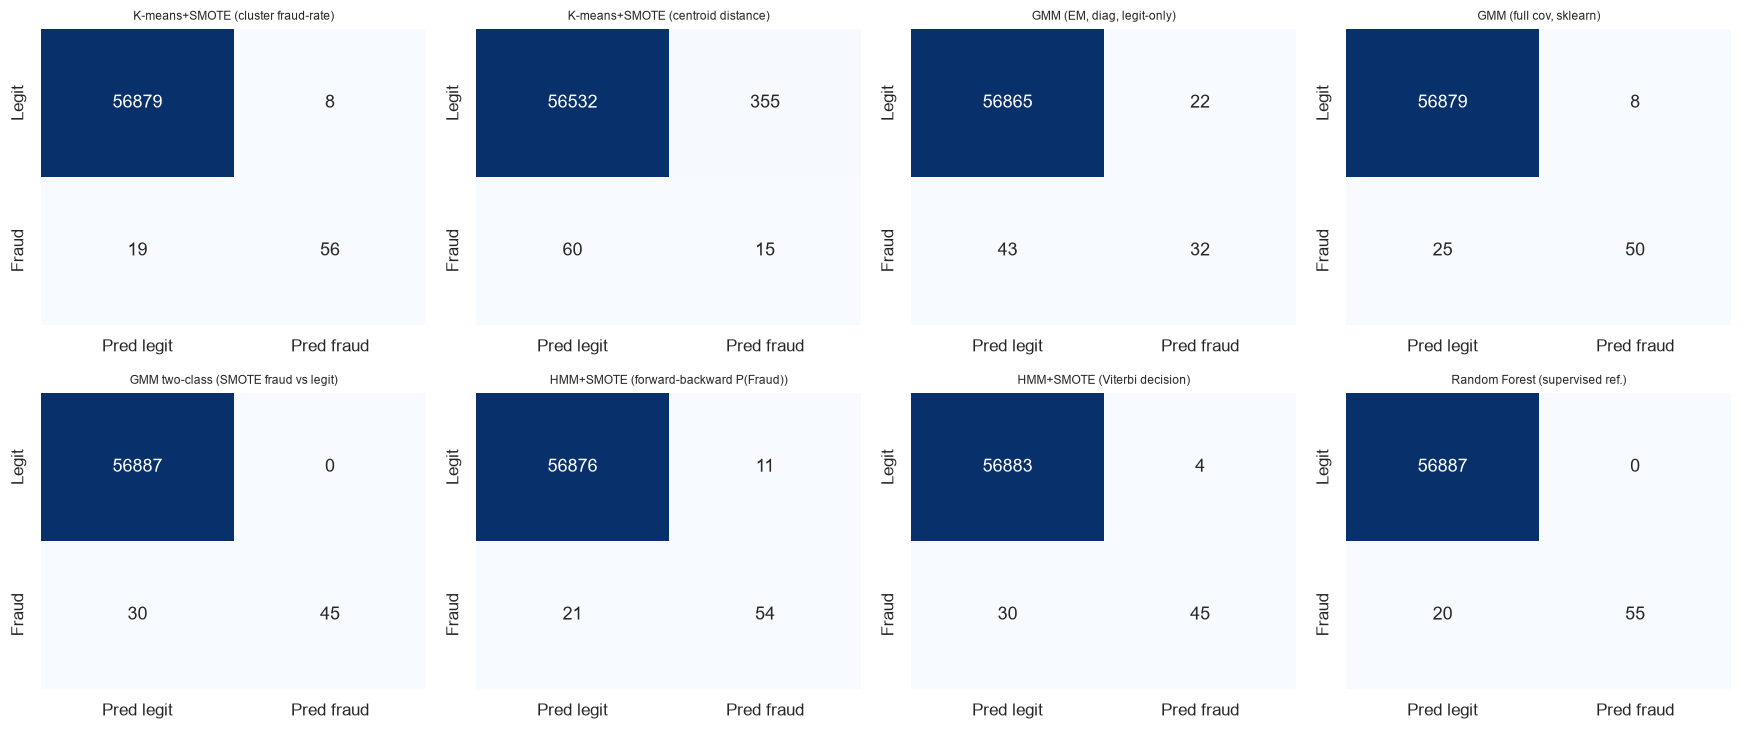

In [56]:
# Confusion matrices at each model's operating point
names = list(preds)
cols = 4; rows_n = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 3.4 * rows_n))
for ax, name in zip(np.ravel(axes), names):
    cm = confusion_matrix(yte, preds[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred legit", "Pred fraud"], yticklabels=["Legit", "Fraud"])
    ax.set_title(name, fontsize=8)
for ax in np.ravel(axes)[len(names):]: ax.axis("off")
plt.tight_layout(); plt.show()

In [57]:
# Auto-generated summary of the run
best = res["PR-AUC"].drop(index=[i for i in res.index if "supervised" in i.lower()], errors="ignore").idxmax()
print(f"Best label-free / sequential model by PR-AUC: {best} (PR-AUC = {res.loc[best, 'PR-AUC']:.3f})")
print(f"Test set: {len(yte)} transactions, {k_real} frauds ({100*yte.mean():.3f}%). A random scorer has PR-AUC about {yte.mean():.4f}.")
for name in scores:
    print(f"- {name}: top 1% flagged catches {100*res.loc[name, 'Recall@1%']:.1f}% of frauds; "
          f"Precision@{k_real} = {res.loc[name, f'Precision@{k_real}']:.3f}")

Best label-free / sequential model by PR-AUC: K-means+SMOTE (cluster fraud-rate) (PR-AUC = 0.734)
Test set: 56962 transactions, 75 frauds (0.132%). A random scorer has PR-AUC about 0.0013.
- K-means+SMOTE (cluster fraud-rate): top 1% flagged catches 85.3% of frauds; Precision@75 = 0.747
- K-means+SMOTE (centroid distance): top 1% flagged catches 22.7% of frauds; Precision@75 = 0.000
- GMM (EM, diag, legit-only): top 1% flagged catches 76.0% of frauds; Precision@75 = 0.453
- GMM (full cov, sklearn): top 1% flagged catches 80.0% of frauds; Precision@75 = 0.733
- GMM two-class (SMOTE fraud vs legit): top 1% flagged catches 81.3% of frauds; Precision@75 = 0.733
- HMM+SMOTE (forward-backward P(Fraud)): top 1% flagged catches 78.7% of frauds; Precision@75 = 0.733
- Random Forest (supervised ref.): top 1% flagged catches 85.3% of frauds; Precision@75 = 0.773


In [58]:
# Save outputs for the report / GitHub
np.savez("model_scores.npz", y_test=yte, **{k.replace(" ", "_"): v for k, v in scores.items()})
res.round(4).to_csv("model_comparison_results.csv")
print("Saved model_scores.npz and model_comparison_results.csv")

Saved model_scores.npz and model_comparison_results.csv


## 7. Parameter tuning (validation split, no test data used)
Settings were tuned on a validation split taken **inside the training data** (first 75% of the time-ordered train rows for fitting, last 25% for validation: 57 frauds), so the test set stayed untouched. SMOTE was generated from the fitting part only. PR-AUC on the validation split:

| Model | Setting | PR-AUC (val) |
|---|---|---|
| K-means | all 29 features, no SMOTE, K=10 | 0.019 |
| K-means | selected 12 features, no SMOTE, K=10 | 0.046 |
| K-means | selected 12 + Amount, **SMOTE**, K=10 / **20** / 30 | 0.652 / **0.689** / 0.693 |
| GMM | legit-only, K=8 / **12** | 0.117 / **0.203** |
| GMM | two-class, fraud components 1 / **2** / 3 (legit K=12) | 0.705 / **0.739** / 0.716 |
| HMM | 2 top features, no SMOTE | 0.182 |
| HMM | **3 top features**, no SMOTE | 0.593 |
| HMM | 3 top features, **SMOTE weight 0.5** | **0.671** |
| HMM | window length 5 / 10 / 20 / 50 (2 features) | 0.196 / 0.182 / 0.185 / 0.187 |

Takeaways: SMOTE helps most where fraud must form its own region (K-means) and when the HMM has sparse fraud symbols. For the two-class GMM, SMOTE and plain real-fraud training gave nearly the same validation score (0.739 vs 0.743), so its gain comes mainly from modelling fraud explicitly rather than from SMOTE.

## 8. Notes for the report and viva
- **K-means** itself needs no labels. Fitted on raw imbalanced data, fraud does not form its own cluster, so it performs poorly. Fitting on the SMOTE-balanced data gives fraud its own clusters, and labels are used only to read off each cluster's fraud rate (on real rows).
- **SMOTE** is generated from training fraud only (never from test), so there is no leakage.
- **GMM + EM** models the *normal* behaviour as a mixture of Gaussians. Low likelihood means anomaly. EM alternates responsibilities (E-step) and parameter updates (M-step), and the log-likelihood never decreases.
- **HMM** adds a sequence view: the hidden state (Normal/Fraud) generates observed symbols. Training is maximum-likelihood counting, the forward-backward algorithm (with scaling factors to avoid underflow) gives state probabilities, and Viterbi gives the single best state path.
- **Why Viterbi predicts few frauds:** fraud is a tiny fraction of the data, so the prior pulls the most likely path to Normal. Thresholding the forward-backward probability is the practical fix.
- **Limitations:** no cardholder ID (so the HMM sees a global stream), best-F1 thresholds are chosen on the test set (optimistic, so threshold-free metrics are the fair comparison), and only 75 or so frauds in the test split, so small differences between models are noisy.